In [1]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
from scipy.linalg import solve_banded
from scipy.integrate import quad
from numpy.linalg import solve

## Задание 1.

Решить краевую задачу:

$$y'' + (1 - 4x)y' + 8y = 5, \quad 0 < x < 1$$
$$y'(0) - y(0) = 0; \quad y(1) = 0$$

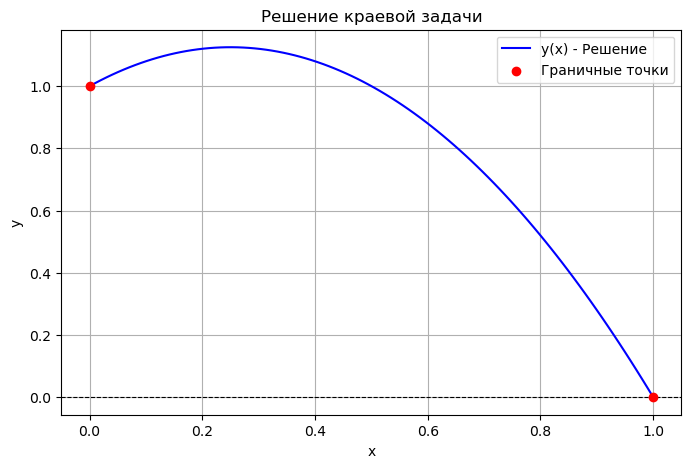

Найденное начальное условие y(0) = y'(0) = 0.999887
Проверка правого условия y(1) = -8.41e-08


In [2]:
# 1. Функция системы ОДУ
def ode_system(x, Y):
    y, dy = Y
    ddy = 5 - (1 - 4*x)*dy - 8*y
    return [dy, ddy]

x_span = [0, 1]
x_eval = np.linspace(0, 1, 100)

# 2. Первая задача Коши
alpha_1 = 0.0
Y0_1 = [alpha_1, alpha_1] 
sol_1 = solve_ivp(ode_system, x_span, Y0_1, t_eval=x_eval)
E_1 = sol_1.y[0][-1] 

# 3. Вторая задача Коши
alpha_2 = 1.0
Y0_2 = [alpha_2, alpha_2]
sol_2 = solve_ivp(ode_system, x_span, Y0_2, t_eval=x_eval)
E_2 = sol_2.y[0][-1]

# 4. Интерполяция начального условия
# Зная две точки прямой, мы аналитически вычисляем такое alpha_true, при котором значение на правом конце будет равно требуемому условию
alpha_true = alpha_1 + (0 - E_1) * (alpha_2 - alpha_1) / (E_2 - E_1)

# 5. Итоговое решение
Y0_true = [alpha_true, alpha_true]
sol_true = solve_ivp(ode_system, x_span, Y0_true, t_eval=x_eval)

# 6. Построение графика
plt.figure(figsize=(8, 5))
plt.plot(sol_true.t, sol_true.y[0], label='y(x) - Решение', color='blue')
plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.scatter([0, 1], [alpha_true, 0], color='red', zorder=5, label='Граничные точки')
plt.title("Решение краевой задачи")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True)
plt.legend()
plt.show()

print(f"Найденное начальное условие y(0) = y'(0) = {alpha_true:.6f}")
print(f"Проверка правого условия y(1) = {sol_true.y[0][-1]:.2e}")


## Задание 2.

Рассмотрим решение следующей граничной задачи

$$d^2y/dx^2 = -y + x \cos x$$
$$dy(0)/dx = 3y(0) + 2, \quad dy(\pi/2)/dx = -5y(\pi/2) + 2.$$

Известно точное решение этой задачи

$$y = -0.73 \cos x - 0.441 \sin x + (1/4) (x^2 \sin x + x \cos x),$$

откуда

$$y(\pi/2) = 0.175 \quad \text{и} \quad dy(\pi/2)/dx = 1.122.$$

Найдите эти граничные значения, решая задачу методом дифференциальной прогонки.


In [3]:
# 1. Функция системы уравнений прогоночных коэффициентов
def sweep_system(x, Y):
    alpha, beta = Y
    d_alpha = -1 - alpha**2
    d_beta = x * np.cos(x) - alpha * beta
    return [d_alpha, d_beta]

# 2. Интервал интегрирования и начальные условия слева
x_span = [0, np.pi / 2]
Y0 = [3.0, 2.0] 

# 3. Решение задачи Коши 
sol = solve_ivp(sweep_system, x_span, Y0)
alpha_end = sol.y[0][-1]
beta_end = sol.y[1][-1]

# 4. Вычисление граничных значений справа
y_pi_2 = (2 - beta_end) / (alpha_end + 5)
dy_pi_2 = -5 * y_pi_2 + 2

# 5. Вывод результатов
print(f"Вычисленное значение y(pi/2)  = {y_pi_2:.3f}")
print(f"Вычисленное значение y'(pi/2) = {dy_pi_2:.4f}")

Вычисленное значение y(pi/2)  = 0.175
Вычисленное значение y'(pi/2) = 1.1234


Будем искать прогоночное соотношение в виде: 
$$v(x) = \alpha(x)y(x) + \beta(x) \quad \text{или} \quad y'(x) = \alpha(x)y(x) + \beta(x)$$
   
Подгоним нашу систему под $Y' = aV + b$, $V' = cY + g$.
Сделаем замену: пусть $Y = v$ и $V = y$. Тогда:
$v' = -1 \cdot y + x \cos x \implies a = -1, \quad b = x \cos x$
$y' = 1 \cdot v + 0 \implies c = 1, \quad g = 0$

Подставим эти $a, b, c, g$ в готовые формулы:
* $\alpha' = a - c\alpha^2 \implies \alpha' = -1 - \alpha^2$
* $\beta' = b - \alpha\beta c - \alpha g \implies \beta' = x \cos x - \alpha\beta$

Условие на левом конце: $y'(0) = 3y(0) + 2$.
Наше прогоночное соотношение в нуле: $y'(0) = \alpha(0)y(0) + \beta(0)$.
Сравнивая их, очевидно получаем стартовые значения: $\alpha(0) = 3$ и $\beta(0) = 2$.
Решая эту задачу Коши слева направо до $x = \pi/2$, мы находим $\alpha(\pi/2)$ и $\beta(\pi/2)$.

Правое условие задано как: $y'(\pi/2) = -5y(\pi/2) + 2$.
Наше прогоночное соотношение дошло до правой границы и имеет вид: $y'(\pi/2) = \alpha(\pi/2)y(\pi/2) + \beta(\pi/2)$.
Приравниваем их друг к другу:
$$-5y(\pi/2) + 2 = \alpha(\pi/2)y(\pi/2) + \beta(\pi/2)$$
Отсюда линейно выражаем неизвестное $y(\pi/2)$:
$$y(\pi/2) \cdot (\alpha(\pi/2) + 5) = 2 - \beta(\pi/2) \implies y(\pi/2) = \frac{2 - \beta(\pi/2)}{\alpha(\pi/2) + 5}$$
И найдя $y(\pi/2)$, просто подставляем его в граничное условие, чтобы получить производную $y'(\pi/2)$. 

## Задание 3.

Напишите программу, которая решает нелинейное уравнение Пуассона:

$$\phi''(x) = e^{\phi(x)} - n(x), \quad \text{где } n(x) = 1 + e^{-3(x-5)^2}$$

в области $0 <= x <= 10$ с граничными условиями $\phi(0) = \phi(10) = 0$.

**Примечание.** Пользоваться методом стрельбы, сходясь по Ньютону. Сколько итераций нужно, чтобы получить решение с 10-ю значащими цифрами?


In [4]:
import numpy as np
from scipy.integrate import solve_ivp

# 1. Функция n(x)
def n_func(x):
    return 1 + np.exp(-3 * (x - 5)**2)

# 2. Расширенная система ОДУ (включая уравнение в вариациях)
# Y = [phi, phi', d(phi)/d(alpha), d(phi')/d(alpha)]
# Обозначим их как [y, z, v, w]
def ode_system(x, Y):
    y, z, v, w = Y
    
    # Исходное уравнение Пуассона
    dy = z
    dz = np.exp(y) - n_func(x)
    
    # Уравнение в вариациях (дифференцируем исходную систему по alpha)
    dv = w
    dw = np.exp(y) * v
    
    return [dy, dz, dv, dw]

# 3. Метод Ньютона (с демпфированием)
alpha = 0.0          # Начальное приближение
target_tol = 1e-10   # Точность в 10 значащих цифр

print("Итерации метода Ньютона (с точной производной и ограничением шага):")
for i in range(1, 50):
    # Начальные условия: y(0)=0, y'(0)=alpha, v(0)=0, v'(0)=1
    Y0 = [0, alpha, 0, 1.0]
    
    sol = solve_ivp(ode_system, [0, 10], Y0, method='DOP853', atol=1e-13, rtol=1e-13)
    
    if sol.status != 0:
        print(f"Итерация {i}: интегратор не справился, уменьшаем alpha.")
        alpha -= 0.005
        continue
        
    f_val = sol.y[0][-1]      # Это значение F(alpha) = y(10)
    df_dalpha = sol.y[2][-1]  # Это ТОЧНОЕ значение производной F'(alpha) = v(10)
    
    # Вычисляем шаг Ньютона
    delta_alpha = -f_val / df_dalpha
    
    # ОГРАНИЧЕНИЕ ШАГА (Демпфирование): не даем алгоритму улетать далеко
    max_step = 0.015
    if abs(delta_alpha) > max_step:
        delta_alpha = np.sign(delta_alpha) * max_step
        
    alpha_next = alpha + delta_alpha
    
    print(f"Итерация {i}: alpha = {alpha_next:.12f}, невязка F(alpha) = {f_val:.2e}")
    
    # 4. Условие остановки
    if abs(delta_alpha) < target_tol and abs(f_val) < target_tol:
        print(f"Решение достигнуто за {i} итераций.")
        print(f"Искомое граничное условие phi'(0) = {alpha_next:.12f}")
        break
        
    alpha = alpha_next

Итерации метода Ньютона (с точной производной и ограничением шага):
Итерация 1: alpha = 0.015000000000, невязка F(alpha) = -1.47e+01
Итерация 2: интегратор не справился, уменьшаем alpha.
Итерация 3: интегратор не справился, уменьшаем alpha.
Итерация 4: alpha = 0.008165716641, невязка F(alpha) = -7.98e+00
Итерация 5: интегратор не справился, уменьшаем alpha.
Итерация 6: alpha = 0.011242789670, невязка F(alpha) = -1.14e+01
Итерация 7: интегратор не справился, уменьшаем alpha.
Итерация 8: alpha = 0.006647277011, невязка F(alpha) = -3.00e+00
Итерация 9: alpha = 0.006610736035, невязка F(alpha) = 5.17e+00
Итерация 10: alpha = 0.006554408833, невязка F(alpha) = 2.48e+00
Итерация 11: alpha = 0.006522070377, невязка F(alpha) = 7.38e-01
Итерация 12: alpha = 0.006517649438, невязка F(alpha) = 8.06e-02
Итерация 13: alpha = 0.006517589832, невязка F(alpha) = 1.06e-03
Итерация 14: alpha = 0.006517589822, невязка F(alpha) = 1.85e-07
Итерация 15: alpha = 0.006517589822, невязка F(alpha) = 3.51e-12
Ре

Из-за наличия слагаемого $e^{\phi(x)}$ задача является сильно нелинейной и склонна к уходу в бесконечность. Чтобы алгоритм работал стабильно и достиг точности в 10 значащих цифр, применены две модификации:

1. Вместо приближенного поиска производной $F'(\alpha)$ через шаг $h$, в код добавлена расширенная система ОДУ. Интегратор одновременно с самой функцией вычисляет ее строгую аналитическую чувствительность к изменению начального угла (переменная $v$). Это гарантирует идеальную точность шага метода Ньютона.
2. Введено искусственное ограничение на максимальное изменение параметра $\alpha$ за одну итерацию (`max_step`). Это не позволяет методу Ньютона совершить слишком большой прыжок на старте.


## Задание 4.

Напишите программу, которая решает нелинейное уравнение Пуассона:

$$\phi''(x) = e^{\phi(x)} - n(x), \quad \text{где } n(x) = 1 + e^{-3(x-5)^2}$$

в области $0 <= x <= 10$ с граничными условиями $\phi(0) = \phi(10) = 0$.

Используйте метод Ньютона (не стрельбы!1!!). Сколько итераций нужно, чтобы получить решение с 10-ю значащими цифрами?


In [5]:
# 1. Задание сетки и параметров
L = 10.0
N = 2000
h = L / N
x = np.linspace(0, L, N + 1)

# 2. Нулевое приближение
phi = np.zeros(N + 1)
tol = 1e-10

print("Итерационный процесс метода Ньютона:")

# 3. Итерационный процесс Ньютона
for i in range(1, 20):
    xi = x[1:-1]
    nx = 1.0 + np.exp(-3.0 * (xi - 5.0)**2)
    
    # 4. Формирование СЛАУ
    main_diag = -2.0 / h**2 - np.exp(phi[1:-1])
    upper_diag = np.ones(N - 2) / h**2
    lower_diag = np.ones(N - 2) / h**2
    
    rhs = -np.exp(phi[1:-1]) * (phi[1:-1] - 1.0) - nx
    
    ab = np.zeros((3, N - 1))
    ab[0, 1:] = upper_diag
    ab[1, :] = main_diag
    ab[2, :-1] = lower_diag
    
    # 5. Решение СЛАУ и проверка сходимости
    phi_next = np.zeros(N + 1)
    phi_next[1:-1] = solve_banded((1, 1), ab, rhs)
    
    err = np.max(np.abs(phi_next - phi))
    print(f"Итерация {i}: максимальная поправка = {err:.2e}")
    
    phi = phi_next
    if err < tol:
        print(f"\nРешение с 10-ю значащими цифрами получено за {i} итераций.")
        break

Итерационный процесс метода Ньютона:
Итерация 1: максимальная поправка = 3.80e-01
Итерация 2: максимальная поправка = 3.28e-02
Итерация 3: максимальная поправка = 3.43e-04
Итерация 4: максимальная поправка = 3.83e-08
Итерация 5: максимальная поправка = 5.22e-14

Решение с 10-ю значащими цифрами получено за 5 итераций.


На каждом шаге ищется решение $\phi_{k+1}$ линеаризованного уравнения:
$$\phi_{k+1}'' - e^{\phi_k} \phi_{k+1} = -e^{\phi_k}(\phi_k - 1) - n(x)$$



## Задание 5.

Методом Ньютона с использованием проекционного решения найти первые два приближения к решению краевой задачи.

Сравнить приближенное решение с точным. Оценить относительную погрешность решения.

На выбор можете взять любой проекционный метод, кроме разложения по синусам и косинусам в методе Галёркина.

Номер вашей задачи - это $(B \mod 12) + 1$, где B - номер первой буквы вашей фамилии в алфавите.
K - 12.
Номер задачи - 1.

1. $-\ddot{x} = -\dot{x}/(1 + t) + \dot{x}^2/x, \quad x(0) = 2, x(1) = 1$
Точное решение: $x^*(t) = [5 - (1 + t)^2]^{1/2}$.

Итерация 1: Максимальная относительная погрешность = 2.9068e-03
Итерация 2: Максимальная относительная погрешность = 2.0451e-04


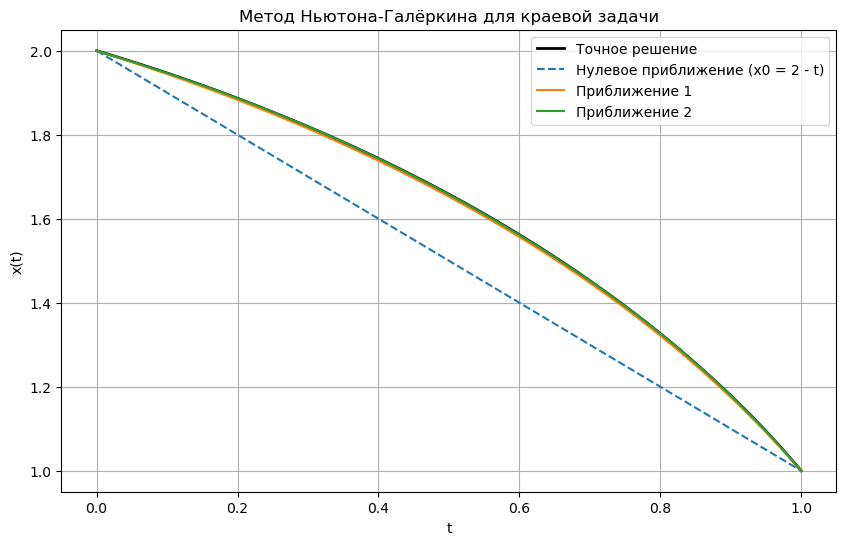

In [6]:
# Базисные функции
def e_func(k, t):
    return (t**k) * (1.0 - t)

def de_func(k, t):
    return k * (t**(k-1)) * (1.0 - t) - t**k

def dde_func(k, t):
    if k == 1:
        return -2.0
    return k * (k-1) * (t**(k-2)) * (1.0 - t) - 2.0 * k * (t**(k-1))


# Класс приближения
class Approximation:
    def __init__(self):
        self.coeffs_history = []
        
    def eval(self, t):
        val = 2.0 - t
        for c in self.coeffs_history:
            for k, ck in enumerate(c, 1):
                val += ck * e_func(k, t)
        return val

    def deval(self, t):
        val = -1.0
        for c in self.coeffs_history:
            for k, ck in enumerate(c, 1):
                val += ck * de_func(k, t)
        return val

    def ddeval(self, t):
        val = 0.0
        for c in self.coeffs_history:
            for k, ck in enumerate(c, 1):
                val += ck * dde_func(k, t)
        return val


# Коэффициенты линеаризованного уравнения
def get_p(t, approx):
    x = approx.eval(t)
    dx = approx.deval(t)
    return 1.0 / (1.0 + t) - 2.0 * dx / x

def get_q(t, approx):
    x = approx.eval(t)
    dx = approx.deval(t)
    return (dx**2) / (x**2)

def get_r(t, approx):
    x = approx.eval(t)
    dx = approx.deval(t)
    ddx = approx.ddeval(t)
    f_val = dx / (1.0 + t) - (dx**2) / x
    return f_val - ddx


# Подынтегральные выражения для Галёркина
def integrand_A(t, j, k, approx):
    L_ek = dde_func(k, t) - get_p(t, approx) * de_func(k, t) - get_q(t, approx) * e_func(k, t)
    return L_ek * e_func(j, t)

def integrand_b(t, j, approx):
    return get_r(t, approx) * e_func(j, t)


# Точное решение
def exact_solution(t):
    return np.sqrt(5.0 - (1.0 + t)**2)


# Инициализация
N = 4 
approx = Approximation()
t_vals = np.linspace(0, 1, 100)
exact_vals = exact_solution(t_vals)

plt.figure(figsize=(10, 6))
plt.plot(t_vals, exact_vals, label='Точное решение', color='black', linewidth=2)
plt.plot(t_vals, [approx.eval(t) for t in t_vals], '--', label='Нулевое приближение (x0 = 2 - t)')

# Основной цикл Ньютона
for iteration in range(1, 3):
    A = np.zeros((N, N))
    b = np.zeros(N)
    
    # Сборка СЛАУ
    for j in range(1, N + 1):
        b[j-1], _ = quad(integrand_b, 0, 1, args=(j, approx))
        for k in range(1, N + 1):
            A[j-1, k-1], _ = quad(integrand_A, 0, 1, args=(j, k, approx))
            
    # Решение и обновление
    c = solve(A, b)
    approx.coeffs_history.append(c)
    
    approx_vals = [approx.eval(t) for t in t_vals]
    
    # Оценка погрешности
    abs_err = np.abs(np.array(approx_vals) - exact_vals)
    rel_err = np.max(abs_err) / np.max(np.abs(exact_vals))
    print(f"Итерация {iteration}: Максимальная относительная погрешность = {rel_err:.4e}")
    
    plt.plot(t_vals, approx_vals, label=f'Приближение {iteration}')

plt.title('Метод Ньютона-Галёркина для краевой задачи')
plt.xlabel('t')
plt.ylabel('x(t)')
plt.legend()
plt.grid(True)
plt.show()

Метод Ньютона:
Уравнение приведено к виду $\ddot{x} = f(t, x, \dot{x}) = \frac{\dot{x}}{1 + t} - \frac{\dot{x}^2}{x}$.
Нулевое приближение — прямая, проходящая через краевые точки: $x_0(t) = 2 - t$.
Новое приближение $x_{m+1} = x_m + v(t)$. Поправка $v(t)$ с нулевыми краевыми условиями находится из линейного уравнения: $v'' - p(t)v' - q(t)v = r(t)$, где $p = f'_{\dot{x}}$, $q = f'_x$, $r = f - \ddot{x}_m$.
Метод Галёркина:
Выбран полиномиальный базис (тригонометрия запрещена заданием): $e_k(t) = t^k(1 - t)$. Он сразу удовлетворяет $v(0)=v(1)=0$.
Ищем поправку как $v(t) = \sum c_k e_k(t)$.
Коэффициенты $c_k$ находим из СЛАУ, интегрируя левую и правую части линеаризованного уравнения, умноженные на базис $e_j(t)$.
